**Vision-Based Gaze Estimation | Presented by: Reza Saadatyar (2026)**

**04 | CNN and Transfer-Learning Gaze Estimation**

![Neural gaze-estimation workflow, learning curves and full outer-LOPO results](../../images/04_cnn_and_transfer_learning.svg)

**Objective:** Compare a compact grayscale CNN and ImageNet-initialised ResNet-18 on the same 7,500 eye images and participant roles as the classical models.

**Results:** Across all 15 held-out participants, Small CNN achieved 7.3048° participant-macro mean angular error and ResNet-18 achieved 8.2304°. The corresponding inner-Validation means were 6.7633° and 8.1554°.

**Scope:** Internal participant-disjoint evaluation on a study-defined MPIIGaze subset, not an external validation or official benchmark.

**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess
repo_url="https://github.com/RezaSaadatyar/Eye-Tracking-Neurocognitive-Intelligence.git"
repo_path=Path("/content")/repo_url.rsplit("/",1)[-1].removesuffix(".git")
if not repo_path.exists():
    subprocess.run(["git","clone","-q",repo_url,str(repo_path)],check=True)

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}

/content/Eye-Tracking-Neurocognitive-Intelligence


**01. Imports and Research Environment**

In [2]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root=setup_colab("vision_based_gaze_estimation")

# ---------------------------- 2. Standard Library ----------------------------
import random
import sys

# ----------------- 3. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd

# ------------------- 4. Machine Learning and Deep Learning -------------------
import torch
from gaze_models import train_gaze_network, predict_network
from gaze_geometry import angular_error_degrees
from mpiigaze_data import restore_indexed_eye_cache
from gaze_evaluation import (load_image_cache, outer_fold_indices,
                             validate_lopo_design,
                             reconcile_outer_predictions)

# ------------------- 5. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure

# ------------------ 6. Shared and Study Research Utilities -------------------
from core.computer_device import computer_device
from core.output_download import download_outputs_from_colab

# ------------------- 7. Reproducibility and Compute Device -------------------
SEED=17
random.seed(SEED)
np.random.seed(SEED)
device=computer_device(min_vram_gb=None)

# ----------------------- 8. Output Directory and Setup -----------------------
out_dir=root/"vision_based_gaze_estimation"/"output"
cache_dir=root/"data"/"processed"/"mpiigaze"
cache_path=cache_dir/"02_normalised_eye_cache.npz"
checkpoint_dir=cache_dir/"checkpoints"
checkpoint_dir.mkdir(parents=True,exist_ok=True)
plot_style(font_family="DejaVu Sans",title_size=12.5,
 title_weight="normal",label_size=11.5,label_weight="normal",
 tick_size=11,legend_size=10,figure_dpi=100,figure_size=(9,4))
print("Study outputs:",out_dir)
print("Local-only model checkpoints:",checkpoint_dir)
print("Python:",sys.version.split()[0])

Local changes kept; continuing with the current checkout. Conflicting Git update deferred.
Compute device and system information
OS: Linux 6.6.159+
CPU: x86_64
Installed RAM: 12.7 GiB
NVIDIA GPU: Tesla T4
Total VRAM: 15.00 GiB
PyTorch version: 2.14.1+cu130
CUDA device: Tesla T4
CUDA runtime: 13.0
cuDNN version: 92800
PyTorch total VRAM: 14.56 GiB
Selected compute device: cuda
Study outputs: /content/Eye-Tracking-Neurocognitive-Intelligence/vision_based_gaze_estimation/output
Local-only model checkpoints: /content/Eye-Tracking-Neurocognitive-Intelligence/data/processed/mpiigaze/checkpoints
Python: 3.13.16


**02. Check Original Images and Fold Identities**

The full run loaded 7,500 source-linked images and 15 fixed participant folds. The cache loader reconciles sample order and target directions with the Notebook 02 index. Missing local images can be restored from exact indexed source rows without resampling or changing folds.

In [3]:
# ================= 02. Verify Current Image and Fold Inputs ==================

required=["02_sample_index.csv","02_fold_assignments.csv"]
missing=[x for x in required if not (out_dir/x).is_file()]
if missing:
    raise FileNotFoundError(f"Notebook 02 outputs missing: {missing}")
# Recover the exact Stage-02 sample rows if this runtime is new.
if not cache_path.is_file():
    restore_indexed_eye_cache(
        root / "data" / "raw" / "mpiigaze",
        out_dir / "02_sample_index.csv", cache_path)
index,images,targets=load_image_cache(
 out_dir/"02_sample_index.csv",cache_path)
folds=pd.read_csv(out_dir/"02_fold_assignments.csv",
 dtype={"participant_id":str,"fold_id":str,"outer_test_person":str})
if folds.duplicated(["fold_id","participant_id"]).any() or folds.empty:
    raise ValueError("Outer-fold source identities are repeated or missing")
validate_lopo_design(index, folds)
print("Matching original image examples:",len(index))
print("Independent people:",index.participant_id.nunique())
print("Available outer folds:",folds.fold_id.nunique())

Matching original image examples: 7500
Independent people: 15
Available outer folds: 15


**03. Configure Full Outer-LOPO Training**

All 15 folds were evaluated. Each contains 6,000 Training images from 12 people, 1,000 inner Validation images from two people and 500 outer Test images from one person. Both networks use AdamW, cosine-direction loss, batch size 128, eight maximum epochs and patience three. Learning rates are 0.001 (Small CNN) and 0.0001 (ImageNet-initialised ResNet-18); fold seeds range from 17 to 31. Outer Test does not guide fitting or checkpoint selection.

In [4]:
# =================== 03. Configure Nested Neural Training ====================

# ------------------- 1. Explicit Compute and Test Settings -------------------
RUN_OUTER_TEST=True
MAX_OUTER_FOLDS=2 if not RUN_OUTER_TEST else None
MODEL_NAMES=("small_cnn","resnet18")
PRETRAINED_RESNET=True
EPOCHS=8
PATIENCE=3
BATCH_SIZE=128
LEARNING_RATE=1e-3

# ------------------------ 2. Preserve Test Boundaries ------------------------
all_folds=sorted(folds.fold_id.unique())
active_folds=(all_folds if MAX_OUTER_FOLDS is None
              else all_folds[:MAX_OUTER_FOLDS])
if RUN_OUTER_TEST and len(active_folds)!=len(all_folds):
    raise ValueError("A final outer LOPO run requires all outer participants")
if not RUN_OUTER_TEST:
    prior=[f for f in ("04_neural_outer_predictions.csv",
                       "04_neural_outer_metrics.csv") if (out_dir/f).exists()]
    if prior:
        raise RuntimeError("Older Test files exist; preserve the current evidence "
                           "and use a clean development checkout: "+str(prior))
print("Current mode:","outer Test" if RUN_OUTER_TEST else "inner Validation development")
print("Outer fold configurations:",len(active_folds),"/",len(all_folds))
print("Model families:",MODEL_NAMES)

Current mode: outer Test
Outer fold configurations: 15 / 15
Model families: ('small_cnn', 'resnet18')


**04. Train Small CNN and ResNet-18 Within Fold Roles**

Small CNN uses three convolutional blocks and 48,387 trainable parameters. ResNet-18 averages pretrained RGB filters for grayscale input and replaces the classification head with a three-component gaze head (11,171,779 parameters). Both select the checkpoint with the lowest inner-Validation angular error.

The full CUDA run on Tesla T4 completed 30 model/fold fits and 238 epochs. All 30 selected checkpoints match the minimum recorded Validation error for their respective fits. Two fits stopped at epoch seven following their best epoch four: Small CNN in outer_07 and ResNet-18 in outer_12. The remaining 28 reached epoch eight.

In [5]:
# =============== 04. Train Fold-Specific CNN and ResNet Models ===============

# ---------------------- 1. Fit Inner Development Models ----------------------
history_rows,inner_metrics,outer_prediction_rows,checkpoint_rows=[],[],[],[]
for fold_i,fold_id in enumerate(active_folds):
    roles=outer_fold_indices(index,folds,fold_id)
    i_train,i_val,i_test=(roles[k] for k in ("train","validation","test"))
    print("Fold:",fold_id,"training people:",index.iloc[i_train].participant_id.nunique(),
          "inner Validation people:",index.iloc[i_val].participant_id.nunique())
    for model_name in MODEL_NAMES:
        pretrained=bool(model_name=="resnet18" and PRETRAINED_RESNET)
        network,history,choice=train_gaze_network(
            model_name,images,targets,i_train,i_val,device=device,
            epochs=EPOCHS,batch_size=BATCH_SIZE,
            seed=SEED+fold_i,pretrained=pretrained,
            learning_rate=(1e-4 if pretrained else LEARNING_RATE),
            patience=PATIENCE)
        for step in history:
            history_rows.append({"fold_id":fold_id,"model":model_name,**step})
        inner_metrics.append({"fold_id":fold_id,"model":model_name,
                              "n_fit_people":index.iloc[i_train].participant_id.nunique(),
                              "n_val_people":index.iloc[i_val].participant_id.nunique(),**choice})
        path=checkpoint_dir/f"04_{model_name}_{fold_id}.pt"
        torch.save({"state_dict":network.state_dict(),"fold_id":fold_id,
                    "model":model_name,"settings":choice},path)
        checkpoint_rows.append({"fold_id":fold_id,"model":model_name,
            "local_relative_path":path.relative_to(root).as_posix(),
            **choice})
        if RUN_OUTER_TEST:
            predicted=predict_network(network,images,i_test,device)
            part=index.iloc[i_test][["sample_id","participant_id"]].copy()
            part["fold_id"]=fold_id
            part["model"]=model_name
            part[["target_x","target_y","target_z"]]=targets[i_test]
            part[["pred_x","pred_y","pred_z"]]=predicted
            outer_prediction_rows.append(part)
        print(model_name,"| best epoch:",choice["best_epoch"],
              "| inner Validation angular error:",
              round(choice["inner_validation_mean_angular_error_deg"],3))

history_table=pd.DataFrame(history_rows)
inner_table=pd.DataFrame(inner_metrics)
checkpoints=pd.DataFrame(checkpoint_rows)
display(inner_table)

Fold: outer_01 training people: 12 inner Validation people: 2
small_cnn | best epoch: 7 | inner Validation angular error: 5.476
resnet18 | best epoch: 8 | inner Validation angular error: 8.447
Fold: outer_02 training people: 12 inner Validation people: 2
small_cnn | best epoch: 6 | inner Validation angular error: 6.705
resnet18 | best epoch: 6 | inner Validation angular error: 7.697
Fold: outer_03 training people: 12 inner Validation people: 2
small_cnn | best epoch: 8 | inner Validation angular error: 6.816
resnet18 | best epoch: 8 | inner Validation angular error: 7.945
Fold: outer_04 training people: 12 inner Validation people: 2
small_cnn | best epoch: 8 | inner Validation angular error: 6.389
resnet18 | best epoch: 8 | inner Validation angular error: 7.722
Fold: outer_05 training people: 12 inner Validation people: 2
small_cnn | best epoch: 8 | inner Validation angular error: 5.791
resnet18 | best epoch: 8 | inner Validation angular error: 7.273
Fold: outer_06 training people: 12 

,fold_id,model,n_fit_people,n_val_people,best_epoch,inner_validation_mean_angular_error_deg,parameters,pretrained
0,outer_01,small_cnn,12,2,7,5.476143,48387,False
1,outer_01,resnet18,12,2,8,8.447427,11171779,True
2,outer_02,small_cnn,12,2,6,6.705383,48387,False
3,outer_02,resnet18,12,2,6,7.697245,11171779,True
4,outer_03,small_cnn,12,2,8,6.815911,48387,False
5,outer_03,resnet18,12,2,8,7.944926,11171779,True
6,outer_04,small_cnn,12,2,8,6.388790,48387,False
7,outer_04,resnet18,12,2,8,7.721796,11171779,True
8,outer_05,small_cnn,12,2,8,5.791054,48387,False
9,outer_05,resnet18,12,2,8,7.273207,11171779,True


**05. Examine Inner Validation and Resource Requirements**

The learning curves report mean Validation error at each observed epoch. Each model has 15 contributing folds at epochs 1–7 and 14 at epoch 8. Later averages can therefore reflect a different group of folds. The mean of per-fold selected checkpoints is distinct from the per-epoch mean.

| Model | Inner Validation (°) | Outer Test (°) |
|---|---:|---:|
| Mean direction | 9.0481 | 9.1601 |
| HOG + Ridge | 7.6961 | 7.5596 |
| Small CNN | 6.7633 | 7.3048 |
| ResNet-18 | 8.1554 | 8.2304 |

All four procedures use the same fixed participants and sample identities. Small CNN has the lowest outer-Test mean, but its difference from HOG + Ridge is only 0.2549°. It has about 231 times fewer parameters than ResNet-18; parameter count is not measured runtime or memory use. The comparison does not isolate the effects of architecture, initialisation or learning rate.

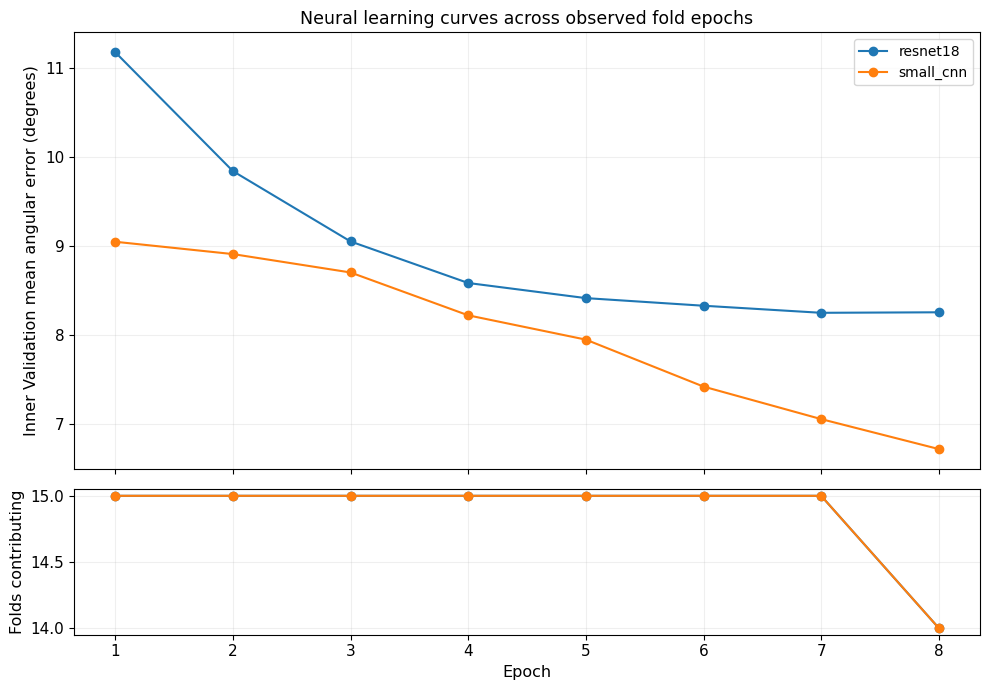

Recorded model checkpoints stay under Git-ignored data/processed/


In [6]:
# =============== 05. Inspect CNN Learning and Inner Validation ===============

# ----------------------- 1. Summarise Observed Epochs ------------------------
epoch_summary = (history_table.groupby(["model", "epoch"])
                 .inner_validation_mean_angular_error_deg
                 .agg(mean_error="mean", n_folds="count").reset_index())
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True,
                         gridspec_kw={"height_ratios": [3, 1]})
for name, group in epoch_summary.groupby("model"):
    line, = axes[0].plot(group.epoch, group.mean_error, marker="o", label=name)
    axes[1].plot(group.epoch, group.n_folds, marker="o", color=line.get_color())
axes[0].set(ylabel="Inner Validation mean angular error (degrees)",
            title="Neural learning curves across observed fold epochs")
axes[0].legend()
axes[1].set(xlabel="Epoch", ylabel="Folds contributing")
axes[1].set_xticks(sorted(epoch_summary.epoch.unique()))
for ax in axes:
    ax.grid(alpha=0.2)
fig.tight_layout()
save_figure(fig, out_dir / "04_validation_curves.png")
plt.show()
print("Recorded model checkpoints stay under Git-ignored data/processed/")

**06. Save Model Evidence and Final Predictions**

The completed run saved 238 history records, 30 selected Validation records, 30 checkpoint metadata records, 30 configuration records, the learning-curve figure, 15,000 matched outer predictions and 30 participant/model metric records. The prediction reconciliation checks sample identity, participant, fold and target direction. Checkpoint weights remain local.

| Outer-Test metric (°) | Small CNN | ResNet-18 |
|---|---:|---:|
| Participant-macro mean | 7.3048 | 8.2304 |
| Median participant mean | 7.2657 | 8.0091 |
| Pooled image median | 6.8695 | 7.7005 |
| Pooled RMSE | 8.2493 | 9.3255 |
| Minimum participant mean | 4.9781 | 6.3302 |
| Maximum participant mean | 9.5559 | 9.6792 |

In [7]:
# =============== 06. Save Neural Development and Test Evidence ===============

# ------------------------ 1. Save Development Tables -------------------------
history_table.to_csv(out_dir / "04_training_history.csv", index=False)
inner_table.to_csv(out_dir / "04_inner_validation_metrics.csv", index=False)
checkpoints.to_csv(out_dir / "04_model_checkpoints.csv", index=False)

# ------------------------ 2. Save Model Configuration ------------------------
configuration = pd.DataFrame([
    {
        "fold_id": fold_id, "model": model_name,
        "run_mode": ("final_outer_lopo" if RUN_OUTER_TEST
                     else "development_inner_validation"),
        "all_outer_folds": len(all_folds),
        "evaluated_folds": len(active_folds),
        "imagenet_pretrained": bool(model_name == "resnet18" and PRETRAINED_RESNET),
        "epochs_max": EPOCHS, "patience": PATIENCE, "batch_size": BATCH_SIZE,
        "learning_rate": (1e-4 if model_name == "resnet18" and PRETRAINED_RESNET
                          else LEARNING_RATE),
        "seed": SEED + fold_i, "test_used_for_model_selection": False,
    }
    for fold_i, fold_id in enumerate(active_folds)
    for model_name in MODEL_NAMES
])
configuration.to_csv(out_dir / "04_run_configuration.csv", index=False)

# ------------------------ 3. Save Outer Test Evidence ------------------------
if RUN_OUTER_TEST:
    predictions=pd.concat(outer_prediction_rows,ignore_index=True)
    predictions, person_metrics = reconcile_outer_predictions(
        predictions, index, folds, MODEL_NAMES)
    predictions.to_csv(out_dir/"04_neural_outer_predictions.csv",index=False)
    person_metrics.to_csv(out_dir/"04_neural_outer_metrics.csv",index=False)
    print("Final outer-person predictions:",len(predictions))
else:
    print("Outer Test not scored; no Test prediction table written")

Final outer-person predictions: 15000


**07. Interpretation and Output Download**

Small CNN has lower outer-Test mean error than ResNet-18 (0.9256° difference), but neither network is uniformly best across participants. Across all four procedures, Small CNN has the lowest participant mean error for eight people, HOG + Ridge for six and the mean-direction reference for one. These are descriptive results; no statistical significance or external generalisation is established.

The seven Stage-04 outputs and complete classical predictions provide the inputs for Notebook 05, which analyses all 30,000 matched predictions without fitting or selecting models. The physical gaze-axis convention remains independently unconfirmed.

In [8]:
# ================== 07. Interpret Neural Results and Export ==================

needed=["04_training_history.csv","04_inner_validation_metrics.csv",
 "04_model_checkpoints.csv","04_run_configuration.csv",
 "04_validation_curves.png"]
if RUN_OUTER_TEST:
    needed+=["04_neural_outer_predictions.csv","04_neural_outer_metrics.csv"]
missing=[x for x in needed if not (out_dir/x).is_file()]
if missing:
    raise FileNotFoundError(f"Notebook 04 stage files missing: {missing}")
print("Recorded inner Validation model/fold configurations:",len(inner_table))
print("No new Test comparison has been used for model selection")
print("Next: 05_cross_person_evaluation_and_robustness.ipynb")
(out_dir / "04_run_configuration.json").unlink(missing_ok=True)
download_outputs_from_colab("vision_based_gaze_estimation/output","04")

Recorded inner Validation model/fold configurations: 30
No new Test comparison has been used for model selection
Next: 05_cross_person_evaluation_and_robustness.ipynb
------------------------------------------------------------------------
Notebook 04
Files packaged: 7
  + 04_inner_validation_metrics.csv
  + 04_model_checkpoints.csv
  + 04_neural_outer_metrics.csv
  + 04_neural_outer_predictions.csv
  + 04_run_configuration.csv
  + 04_training_history.csv
  + 04_validation_curves.png
Download ZIP from Colab Contents: /content/vision_based_gaze_estimation_Notebook_04_Outputs.zip
